# Prédiction des frais d'assurance médicale

## Objectif
Ce notebook cherche à **prédire les frais d'assurance médicale (`charges`)** d'un assuré à partir de ses caractéristiques personnelles. Trois modèles de régression sont entraînés puis comparés :

1. **Régression linéaire** (modèle de référence)
2. **Random Forest** (forêt d'arbres de décision)
3. **MLP** (réseau de neurones multicouche)

## Jeu de données
Fichier : `data/insurance.csv` — 1 338 assurés, 7 colonnes, aucune valeur manquante.

| Colonne | Type | Description |
|---|---|---|
| `age` | entier | Âge de l'assuré (18 à 64 ans) |
| `sex` | catégorie | Sexe (`female` / `male`) |
| `bmi` | réel | Indice de masse corporelle (IMC) |
| `children` | entier | Nombre d'enfants à charge (0 à 5) |
| `smoker` | catégorie | Fumeur (`yes` / `no`) |
| `region` | catégorie | Région de résidence aux États-Unis (`northeast`, `northwest`, `southeast`, `southwest`) |
| `charges` | réel | **Variable cible** : frais médicaux facturés (en dollars) |

## Sommaire
1. Installation des dépendances
2. Chargement des données
3. Exploration des données
4. Visualisation des relations
5. Prétraitement
6. Séparation entraînement / test
7. Modèle 1 : Régression linéaire
8. Modèle 2 : Random Forest (et importance des variables)
9. Modèle 3 : Réseau de neurones (MLP)
10. Comparaison et conclusion

---
## 1. Installation des dépendances
Toutes les bibliothèques sont installées en une seule cellule : `pandas`, `scikit-learn`, `seaborn`, `matplotlib`. Elle n'est à exécuter qu'une fois par environnement.


In [30]:
%pip install pandas scikit-learn  seaborn matplotlib;

Note: you may need to restart the kernel to use updated packages.


## 2. Chargement des données
On lit le fichier CSV dans un `DataFrame` pandas et on affiche les premières lignes pour vérifier la structure.

In [31]:
import pandas as pd

data = pd.read_csv('data/insurance.csv')
data.head()


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## 3. Exploration des données
Trois vérifications rapides :
- `info()` : types des colonnes et nombre de valeurs non nulles ;
- `isna().sum()` : nombre de valeurs manquantes par colonne (**aucune** ici) ;
- `describe()` : statistiques descriptives des variables numériques.

**Observations :**
- L'âge moyen est d'environ 39 ans et l'IMC moyen d'environ 30,7.
- Les frais (`charges`) sont très dispersés : de ~1 100 \$ à ~63 800 \$, avec une moyenne (13 270 \$) nettement supérieure à la médiane (9 382 \$). La distribution est donc **asymétrique à droite** : quelques assurés ont des frais très élevés.

In [32]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [33]:
data.isna().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [34]:
data.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,1338.0,39.21,14.05,18.00,27.00,39.00,51.00,64.00
bmi,1338.0,30.66,6.10,15.96,26.30,30.40,34.69,53.13
children,1338.0,1.09,1.21,0.00,0.00,1.00,2.00,5.00
charges,1338.0,13270.42,12110.01,1121.87,4740.29,9382.03,16639.91,63770.43


## 4. Visualisation des relations

### Âge vs frais
Nuage de points de `charges` en fonction de `age`. On s'attend à ce que les frais augmentent avec l'âge. On observe plusieurs « bandes » distinctes, ce qui suggère qu'une autre variable sépare les assurés en groupes.

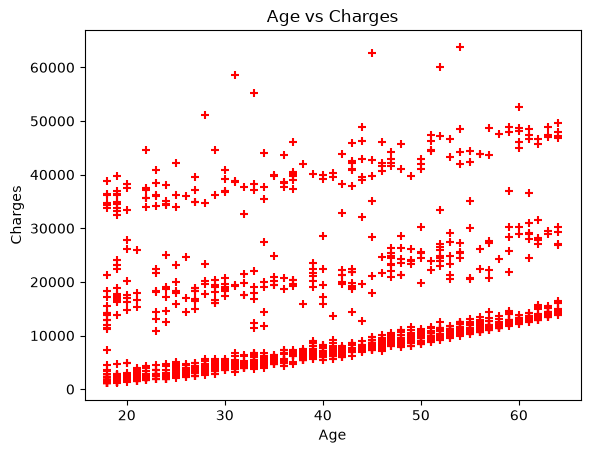

In [35]:
import matplotlib.pyplot as plt
plt.scatter(data['age'], data['charges'], color='red', marker='+')
plt.xlabel('Age')
plt.ylabel('Charges')
plt.title('Age vs Charges')
plt.show()

### Âge vs frais, selon le statut fumeur
Même graphique avec une couleur par statut fumeur (`hue="smoker"`). Les bandes s'expliquent : **les fumeurs ont des frais nettement plus élevés** que les non-fumeurs à âge égal. Le tabagisme est donc probablement la variable la plus déterminante.

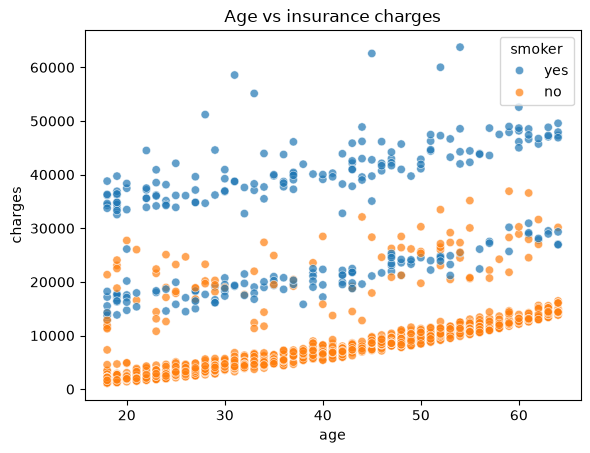

In [36]:
import seaborn as sns
sns.scatterplot(data=data,x="age",y="charges",hue="smoker",alpha=.7)
plt.title("Age vs insurance charges")
plt.show()

### IMC vs frais, selon le statut fumeur
Chez les non-fumeurs, l'IMC influence peu les frais. Chez les fumeurs, les frais augmentent fortement au-delà d'un IMC d'environ 30 (obésité). Il y a donc une **interaction** entre `bmi` et `smoker`, qu'un modèle linéaire simple ne peut pas capturer directement, contrairement aux modèles non linéaires (Random Forest, MLP).

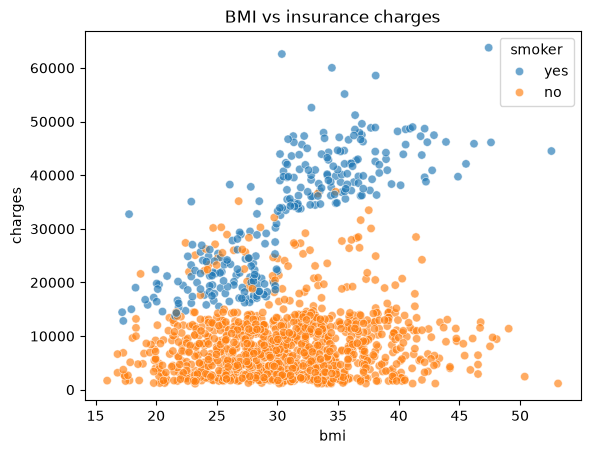

In [37]:
sns.scatterplot(data=data,x="bmi",y="charges",hue="smoker",alpha=.65)
plt.title("BMI vs insurance charges")
plt.show()


## 5. Prétraitement

### Encodage des variables catégorielles
Les modèles de scikit-learn n'acceptent que des valeurs numériques. Deux méthodes d'encodage sont utilisées selon le type de variable.

**Variables binaires → `LabelEncoder`** (ordre alphabétique) :
- `sex` : female → 0, male → 1
- `smoker` : no → 0, yes → 1

Avec seulement deux valeurs, un codage 0/1 n'introduit aucun ordre artificiel.

**Variable à plusieurs modalités → encodage *one-hot*** (`pd.get_dummies`) :

`region` est remplacée par une colonne 0/1 par région :

| region | `region_northwest` | `region_southeast` | `region_southwest` |
|---|---|---|---|
| northeast | 0 | 0 | 0 |
| northwest | 1 | 0 | 0 |
| southeast | 0 | 1 | 0 |
| southwest | 0 | 0 | 1 |

- `drop_first=True` supprime la colonne `region_northeast` : **northeast devient la région de référence**. Sans cela, les quatre colonnes additionnées vaudraient toujours 1, ce qui ferait doublon avec la constante du modèle linéaire (piège des variables muettes).
- `dtype=int` produit des 0/1 au lieu de `True`/`False`.

Contrairement à un codage 0–3, chaque région reçoit ainsi son propre coefficient, sans ordre imposé entre les régions.


In [38]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
data['sex'] = le.fit_transform(data['sex'])
data['smoker'] = le.fit_transform(data['smoker'])

# One-hot pour region (au lieu de LabelEncoder)
data = pd.get_dummies(data, columns=['region'], drop_first=True, dtype=int)


### Variables explicatives, cible et corrélations
- `y` : la variable cible `charges` ;
- `X` : toutes les autres colonnes, soit 8 variables explicatives (`age`, `sex`, `bmi`, `children`, `smoker`, `region_northwest`, `region_southeast`, `region_southwest`).

La carte de chaleur affiche la corrélation de Pearson entre chaque paire de variables explicatives (de -1 à 1). Elle permet de repérer une éventuelle **multicolinéarité** (variables explicatives très corrélées entre elles), qui rendrait les coefficients de la régression linéaire difficiles à interpréter.

**Lecture :**
- Les corrélations entre variables explicatives restent faibles. La plus notable est `bmi` / `region_southeast` (≈ 0,27) : les assurés du sud-est ont en moyenne un IMC plus élevé.
- Les colonnes `region_*` sont négativement corrélées entre elles (≈ -0,33). C'est normal : un assuré ne peut appartenir qu'à une seule région, donc ces colonnes ne peuvent pas valoir 1 en même temps.

Text(0.5, 1.0, 'Numeric feature correlations')

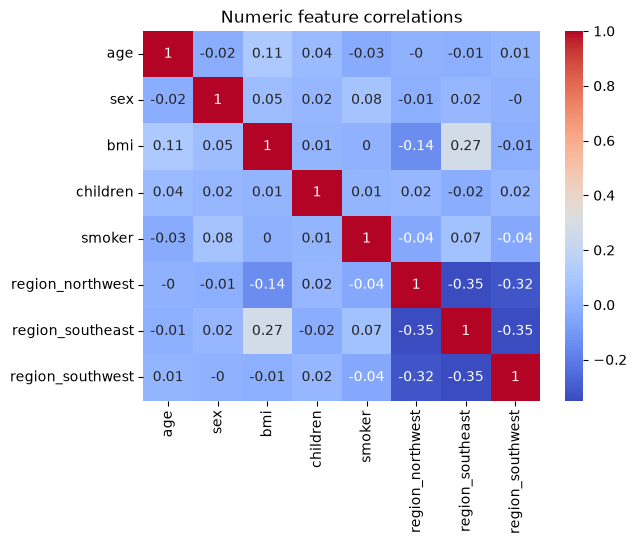

In [39]:

y = data['charges']
X = data.drop(columns=['charges'])

sns.heatmap(X.corr().round(2), cmap='coolwarm', annot=True)
plt.title("Numeric feature correlations")

## 6. Séparation entraînement / test
Les données sont découpées en :
- **80 % pour l'entraînement** (`x_train`, `y_train`) : utilisé pour ajuster les modèles ;
- **20 % pour le test** (`x_test`, `y_test`) : données jamais vues, utilisées pour mesurer la capacité de généralisation.

`random_state=42` fixe le tirage aléatoire pour que les résultats soient reproductibles.

In [40]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## 7. Modèle 1 : Régression linéaire
La régression linéaire modélise la cible comme une combinaison linéaire des variables :

$$\hat{y} = \beta_0 + \beta_1 \cdot age + \beta_2 \cdot sex + \beta_3 \cdot bmi + \beta_4 \cdot children + \beta_5 \cdot smoker + \beta_6 \cdot reg_{NW} + \beta_7 \cdot reg_{SE} + \beta_8 \cdot reg_{SW}$$

- `model.intercept_` : l'ordonnée à l'origine $\beta_0$ (≈ -11 931) ;
- `model.coef_` : les coefficients $\beta_1 \dots \beta_8$, dans l'ordre des colonnes de `X`.

**Interprétation des coefficients obtenus** (toutes choses égales par ailleurs) :

| Variable | Coefficient | Lecture |
|---|---|---|
| `age` | ≈ +257 | +257 \$ par année d'âge |
| `sex` | ≈ -19 | effet négligeable |
| `bmi` | ≈ +337 | +337 \$ par point d'IMC |
| `children` | ≈ +425 | +425 \$ par enfant |
| `smoker` | ≈ **+23 651** | être fumeur ajoute environ 23 650 \$ |
| `region_northwest` | ≈ -371 | -371 \$ par rapport au northeast |
| `region_southeast` | ≈ -658 | -658 \$ par rapport au northeast |
| `region_southwest` | ≈ -810 | -810 \$ par rapport au northeast |

Grâce à l'encodage one-hot, les coefficients de région se lisent directement comme un **écart par rapport à la région de référence** (northeast). L'effet de la région reste faible comparé à celui du tabagisme.

> 💡 Pour afficher chaque coefficient en face du nom de sa variable : `pd.Series(model.coef_, index=X.columns)`.

In [41]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()


model.fit(x_train, y_train)

print(model.intercept_)
print(model.coef_)

-11931.21905032667
[ 2.56975706e+02 -1.85916916e+01  3.37092552e+02  4.25278784e+02
  2.36511289e+04 -3.70677326e+02 -6.57864297e+02 -8.09799354e+02]


### Prédictions
On compare les valeurs réelles et prédites sur les 10 premières lignes, d'abord sur le jeu d'entraînement, puis sur le jeu de test.

In [42]:
predicted = model.predict(x_train)
print(pd.DataFrame({'Actual': y_train, 'Predicted': predicted}).head(10).round(2))

        Actual  Predicted
560    9193.84    7094.54
1285   8534.67    8344.73
1142  27117.99    9153.77
969    8596.83   11128.38
486   12475.35   10088.01
170   13405.39   17561.02
277    2150.47    1103.80
1033  13747.87   23596.28
209    6610.11   12652.82
947   39047.29   33163.26


In [43]:
predicted_test = model.predict(x_test)
print(pd.DataFrame({'Actual': y_test, 'Predicted': predicted_test}).head(10).round(2))

        Actual  Predicted
764    9095.07    8969.55
887    5272.18    7068.75
890   29330.98   36858.41
1293   9301.89    9454.68
259   33750.29   26973.17
1312   4536.26   10864.11
899    2117.34     170.28
752   14210.54   16903.45
1286   3732.63    1092.43
707   10264.44   11218.34


### Évaluation
Trois métriques sont calculées sur l'entraînement et sur le test :
- **MAE** (*Mean Absolute Error*) : erreur absolue moyenne, en dollars. Plus elle est faible, mieux c'est.
- **MSE** (*Mean Squared Error*) : moyenne des erreurs au carré. Elle pénalise davantage les grosses erreurs (unité : dollars²).
- **R²** (coefficient de détermination) : part de la variance de `charges` expliquée par le modèle (1 = parfait, 0 = pas mieux que prédire la moyenne).

Comparer train et test permet de détecter un **surapprentissage** (bon score en train, mauvais en test).

In [44]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print('MAE train:', mean_absolute_error(y_train, predicted).__round__(2))
print('MSE train:', mean_squared_error(y_train, predicted).__round__(2))
print('R-Squared train:', r2_score(y_train, predicted).__round__(2))

print('MAE test:', mean_absolute_error(y_test, predicted_test).__round__(2))
print('MSE test:', mean_squared_error(y_test, predicted_test).__round__(2))
print('R-Squared test:', r2_score(y_test, predicted_test).__round__(2))

MAE train: 4208.23
MSE train: 37277681.7
R-Squared train: 0.74
MAE test: 4181.19
MSE test: 33596915.85
R-Squared test: 0.78


**Résultats :** R² ≈ 0,74 (train) et 0,78 (test), MAE test ≈ 4 181 \$. Les scores sont proches entre train et test : pas de surapprentissage, mais le modèle reste limité car il ne capture pas les effets non linéaires (interaction IMC × fumeur). L'encodage one-hot de `region` ne change presque pas les scores (la région influence peu les frais), mais il rend les coefficients correctement interprétables.

### Valeurs réelles vs prédites (jeu de test)
Chaque point est un assuré du **jeu de test**, que le modèle n'a jamais vu pendant l'entraînement. La droite rouge en pointillés représente une prédiction parfaite : plus les points en sont proches, meilleur est le modèle.

On distingue plusieurs groupes de points. Pour les frais élevés, en particulier chez les fumeurs avec un IMC élevé, le modèle linéaire s'écarte nettement de la droite : c'est la conséquence de l'interaction IMC × fumeur qu'il ne sait pas représenter.

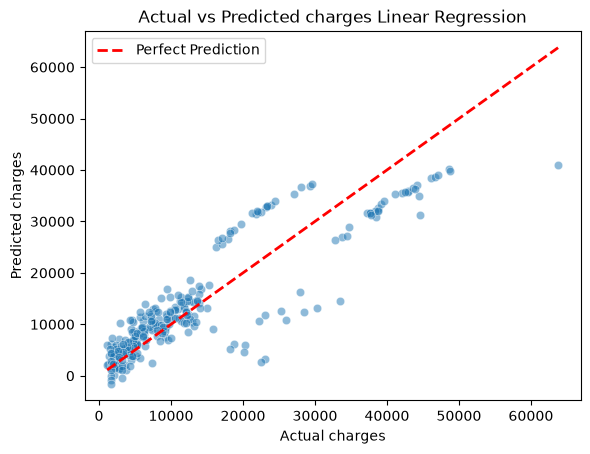

In [45]:
sns.scatterplot(x=y_test, y=predicted_test, alpha=.5);
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Perfect Prediction');
plt.title("Actual vs Predicted charges Linear Regression");
plt.xlabel("Actual charges"); 
plt.ylabel("Predicted charges"); 
plt.legend(); 
plt.show()


## 8. Modèle 2 : Random Forest
Une forêt aléatoire combine de nombreux arbres de décision, chacun entraîné sur un échantillon aléatoire des données ; la prédiction finale est la moyenne des arbres. Elle capture naturellement les relations non linéaires et les interactions.

Hyperparamètres utilisés :
- `n_estimators=100` : nombre d'arbres ;
- `max_depth=4` : profondeur maximale de chaque arbre. Une profondeur faible limite le surapprentissage (voir la comparaison plus bas) ;
- `min_samples_split=2` : nombre minimal d'échantillons pour diviser un nœud ;
- `min_samples_leaf=3` : nombre minimal d'échantillons dans une feuille (limite les feuilles trop spécifiques) ;
- `n_jobs=-1` : utilise tous les cœurs du processeur ;
- `random_state=42` : reproductibilité.

In [46]:
from sklearn.ensemble import RandomForestRegressor
modelRandomForest = RandomForestRegressor(n_estimators=100, max_depth=4, min_samples_split=2, min_samples_leaf=3, n_jobs=-1, random_state=42)


modelRandomForest.fit(x_train, y_train)
predictedRf_train = modelRandomForest.predict(x_train)

predictedRf_test = modelRandomForest.predict(x_test)

print(pd.DataFrame({'Actual_train': y_train, 'Predicted_train': predictedRf_train}).head(10).round(2))
print(pd.DataFrame({'Actual_test': y_test, 'Predicted_test': predictedRf_test}).head(10).round(2))

      Actual_train  Predicted_train
560        9193.84         10003.50
1285       8534.67         10578.06
1142      27117.99         11817.82
969        8596.83          7663.43
486       12475.35         13022.90
170       13405.39         14390.95
277        2150.47          2987.63
1033      13747.87         16348.29
209        6610.11          6881.78
947       39047.29         42012.33
      Actual_test  Predicted_test
764       9095.07         9817.09
887       5272.18         6145.36
890      29330.98        27534.12
1293      9301.89        10078.15
259      33750.29        35470.91
1312      4536.26         6486.94
899       2117.34         2800.14
752      14210.54        14242.67
1286      3732.63         5391.80
707      10264.44        11179.38


### Évaluation de la Random Forest
Mêmes métriques que pour la régression linéaire.

In [47]:
print('MAE train:', mean_absolute_error(y_train, predictedRf_train).__round__(2))
print('MSE train:', mean_squared_error(y_train, predictedRf_train).__round__(2))
print('R-Squared train:', r2_score(y_train, predictedRf_train).__round__(2))

print('MAE test:', mean_absolute_error(y_test, predictedRf_test).__round__(2))
print('MSE test:', mean_squared_error(y_test, predictedRf_test).__round__(2))
print('R-Squared test:', r2_score(y_test, predictedRf_test).__round__(2))

MAE train: 2443.41
MSE train: 18638870.93
R-Squared train: 0.87
MAE test: 2569.86
MSE test: 19580886.45
R-Squared test: 0.87


**Résultats :** R² ≈ 0,87 (train) et 0,87 (test), MAE test ≈ 2 570 \$. C'est une nette amélioration par rapport à la régression linéaire, **sans surapprentissage** : les scores d'entraînement et de test sont identiques.

**Choix de la profondeur des arbres (`max_depth`) :**

| | R² train | R² validation croisée (5 plis) | R² test | MAE test |
|---|---|---|---|---|
| `max_depth=4` (actuel) | 0,87 | **0,847** | 0,874 | ≈ 2 570 \$ |
| `max_depth=10` | 0,92 | 0,838 | 0,875 | ≈ 2 480 \$ |

- Des arbres plus profonds (`max_depth=10`) font monter le score d'entraînement (0,92) sans améliorer le R² test : c'est un **léger surapprentissage**.
- Une validation croisée (`GridSearchCV`, 5 plis sur le jeu d'entraînement, `max_depth` ∈ {3, 4, 5, 6, 8, 10}) donne le meilleur score de validation pour **`max_depth=4`**. Les écarts entre profondeurs restent faibles (R² de 0,838 à 0,847, pour un écart-type d'environ 0,04 entre les plis).
- `max_depth=4` est donc le choix le plus défendable : même capacité de généralisation, avec un modèle plus simple.

### Importance des variables
La Random Forest construit ses arbres en coupant les données en deux à chaque étape (par exemple `smoker <= 0.5` ou `bmi <= 30`), et chaque coupure fait baisser l'erreur. `feature_importances_` donne, pour chaque variable, la **part de cette baisse d'erreur** obtenue grâce à elle, sur l'ensemble des arbres. Le total des importances vaut 1.

Le graphique trie les variables par importance. La valeur n'est affichée que pour celles qui dépassent 1 %.

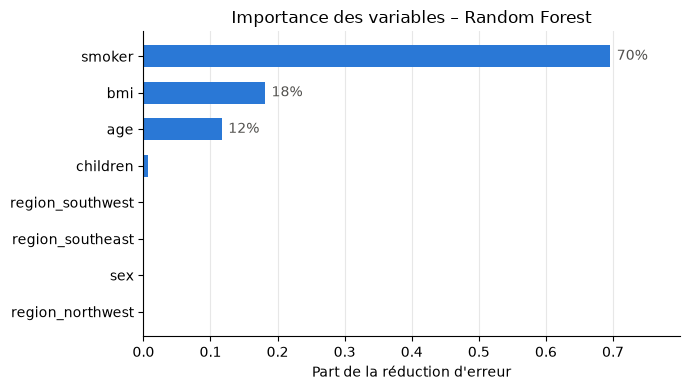

In [48]:
importances = pd.Series(modelRandomForest.feature_importances_, index=X.columns).sort_values()

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(importances.index, importances.values, color='#2a78d6', height=0.6)

# Valeur affichée au bout des barres, uniquement pour les variables qui comptent (≥ 1 %)
for i, v in enumerate(importances.values):
    if v >= 0.01:
        ax.text(v + 0.01, i, f"{v:.0%}", va='center', color='#52514e')

ax.set_title("Importance des variables – Random Forest")
ax.set_xlabel("Part de la réduction d'erreur")
ax.set_xlim(0, importances.max() * 1.15)
ax.xaxis.grid(True, alpha=0.3)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()


**Lecture :**

| Variable | Importance |
|---|---|
| `smoker` | ≈ 70 % |
| `bmi` | ≈ 18 % |
| `age` | ≈ 12 % |
| `children` | ≈ 1 % |
| `sex`, `region_*` | ≈ 0 % |

- Le **statut fumeur** explique à lui seul plus des deux tiers de la performance du modèle.
- L'**IMC** arrive en deuxième position, devant l'âge, alors que son coefficient linéaire semblait modeste. La forêt exploite son effet combiné avec le tabagisme (au-delà d'un IMC de 30 chez les fumeurs), que la régression linéaire ne voit pas.
- Le sexe, la région et le nombre d'enfants n'apportent presque rien. Avec `max_depth=4`, chaque arbre ne fait que quelques coupures, et elles sont presque toutes consacrées aux trois variables principales.

> 💡 **Limites :** cette importance est calculée sur les données d'entraînement et favorise les variables qui ont beaucoup de valeurs différentes (`bmi`, `age`). L'importance par permutation (`sklearn.inspection.permutation_importance`), calculée sur le jeu de test, est plus fiable. Elle mesure de combien le score baisse quand on mélange une colonne, et elle fonctionne aussi pour le MLP. Elle donne ici le même classement (smoker > bmi > age).

## 9. Modèle 3 : Réseau de neurones (MLP)

### Normalisation des variables
Les variables ont des échelles très différentes (0–1 pour `smoker`, 18–64 pour `age`…). Un réseau de neurones, entraîné par descente de gradient, converge mal dans ce cas. On normalise donc chaque variable avec un `StandardScaler` (moyenne 0, écart-type 1) :

$$z = \frac{x - \text{moyenne}}{\text{écart-type}}$$

Le scaler et le modèle sont enchaînés dans un **`Pipeline`** (`make_pipeline`). Lors de `fit`, la moyenne et l'écart-type sont calculés **uniquement sur `x_train`**, puis réappliqués tels quels à `x_test` lors de `predict`. Cela évite toute **fuite de données** du jeu de test vers l'entraînement.

### Le modèle
Le `MLPRegressor` est un réseau de neurones entièrement connecté :
- `hidden_layer_sizes=(100, 50, 20, 10, 5)` : 5 couches cachées de taille décroissante ;
- `activation='relu'` : fonction d'activation ReLU ;
- `max_iter=2000` : nombre maximal d'itérations d'entraînement (une limite haute, qui n'est pas atteinte grâce à l'arrêt anticipé) ;
- `early_stopping=True` : **arrêt anticipé** (voir ci-dessous) ;
- `random_state=42` : reproductibilité de l'initialisation des poids et du choix des données de validation.

### Arrêt anticipé (`early_stopping=True`)
Sans arrêt anticipé, le réseau continue d'apprendre tant qu'il améliore son score sur l'entraînement, quitte à « apprendre par cœur » les données. Avec `early_stopping=True` :
1. 10 % du jeu d'entraînement est mis de côté comme **jeu de validation** (`validation_fraction=0.1` par défaut) ;
2. après chaque itération, le R² est calculé sur ce jeu de validation ;
3. si ce score ne progresse plus pendant 10 itérations consécutives (`n_iter_no_change=10`), l'entraînement s'arrête.

Ici, l'entraînement s'arrête après **376 itérations** (sur 2 000 autorisées), avec un R² de validation d'environ 0,87. L'avertissement `ConvergenceWarning` disparaît, et le surapprentissage observé sans arrêt anticipé est évité.

In [49]:
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline


modelMLP = make_pipeline(
    StandardScaler(), 
    MLPRegressor(hidden_layer_sizes=(100, 50, 20, 10, 5), activation='relu', max_iter=2000, early_stopping=True, random_state=42))

modelMLP.fit(x_train, y_train)
predictedMLP_train = modelMLP.predict(x_train)

predictedMLP_test = modelMLP.predict(x_test)

print(pd.DataFrame({'Actual_train': y_train, 'Predicted_train': predictedMLP_train}).head(10).round(2))
print(pd.DataFrame({'Actual_test': y_test, 'Predicted_test': predictedMLP_test}).head(10).round(2))

      Actual_train  Predicted_train
560        9193.84         10299.04
1285       8534.67          9626.49
1142      27117.99         11922.60
969        8596.83         11754.73
486       12475.35         12684.89
170       13405.39         13885.88
277        2150.47          4626.90
1033      13747.87         13078.88
209        6610.11          6781.80
947       39047.29         39845.47
      Actual_test  Predicted_test
764       9095.07         9869.12
887       5272.18         6110.99
890      29330.98        31967.98
1293      9301.89        10367.72
259      33750.29        28977.51
1312      4536.26         5586.24
899       2117.34         4059.61
752      14210.54        16067.13
1286      3732.63         7042.45
707      10264.44        11831.53


### Évaluation du MLP
Mêmes métriques, arrondies à 2 décimales.

In [50]:
print('MAE train:', mean_absolute_error(y_train, predictedMLP_train).__round__(2))
print('MSE train:', mean_squared_error(y_train, predictedMLP_train).__round__(2))
print('R-Squared train:', r2_score(y_train, predictedMLP_train).__round__(2))

print('MAE test:', mean_absolute_error(y_test, predictedMLP_test).__round__(2))
print('MSE test:', mean_squared_error(y_test, predictedMLP_test).__round__(2))
print('R-Squared test:', r2_score(y_test, predictedMLP_test).__round__(2))

MAE train: 2716.34
MSE train: 20984771.25
R-Squared train: 0.85
MAE test: 2670.2
MSE test: 20998501.16
R-Squared test: 0.86


**Résultats :** R² ≈ 0,85 (train) et 0,86 (test), MAE test ≈ 2 670 \$.

**Comparaison des réglages testés pour le MLP normalisé :**

| Réglage | Itérations | R² train | R² test | MAE test |
|---|---|---|---|---|
| `max_iter=1000` | 1 000 (non convergé) | 0,88 | 0,85 | ≈ 2 798 \$ |
| `max_iter=2000` | ≈ 1 750 (convergé) | 0,91 | 0,83 | ≈ 3 092 \$ |
| `max_iter=2000, early_stopping=True` (actuel) | 376 | 0,85 | **0,86** | **≈ 2 670 \$** |

- L'arrêt anticipé donne le **meilleur score de test** des trois réglages, et la plus faible erreur moyenne.
- Le score d'entraînement baisse (0,85), au point d'être légèrement inférieur au score de test (0,86). Le modèle n'apprend plus les particularités du jeu d'entraînement : **il n'y a plus de surapprentissage**.
- C'est le compromis recherché : un score d'entraînement un peu moins bon, en échange d'une meilleure généralisation sur de nouvelles données.

## 10. Comparaison et conclusion

| Modèle | MAE test (\$) | R² train | R² test | Écart train/test |
|---|---|---|---|---|
| Régression linéaire | ≈ 4 181 | 0,74 | 0,78 | aucun |
| Random Forest (`max_depth=4`) | **≈ 2 570** | 0,87 | **0,87** | aucun |
| MLP normalisé (`early_stopping=True`) | ≈ 2 670 | 0,85 | 0,86 | aucun |

**Conclusions :**
- La **Random Forest** reste le meilleur modèle sur le jeu de test (R² 0,87, MAE ≈ 2 570 \$), sans surapprentissage grâce à des arbres peu profonds.
- Le **MLP**, avec normalisation et arrêt anticipé, arrive très près (R² test 0,86, MAE ≈ 2 670 \$), lui aussi sans surapprentissage. L'écart entre les deux modèles est faible : sur un autre découpage train/test, le classement pourrait s'inverser.
- La **régression linéaire** sert de référence : simple et interprétable, mais elle ne capture pas l'effet combiné IMC × fumeur, d'où une erreur nettement plus élevée.
- Le **statut fumeur** est de loin le facteur le plus déterminant des frais (≈ 70 % de l'importance dans la Random Forest), suivi de l'IMC et de l'âge. Le sexe, la région et le nombre d'enfants ont un effet faible.


**Pistes d'amélioration restantes :**
- Validation croisée pour comparer la Random Forest et le MLP sur plusieurs découpages, et vérifier que l'écart entre eux est réel ;
- Transformation logarithmique de `charges` pour réduire l'asymétrie.